# LightGBM Model

Stage 2 of Question B's feature selection and the main forecasting model. Reads
the Stage 1 screened dataset from
[`../Feature Selection/Output/`](../Feature%20Selection/Output/).


## Setup

Install LightGBM and import the libraries used throughout.

In [1]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silence a harmless joblib warning on Windows

import time
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


## Configurations

Paths, target column, baseline names, the LightGBM parameter grid, and the
thresholds that decide which features get dropped.

The model data and the feature dictionary come from
[`../Feature Selection/Output/`](../Feature%20Selection/Output/) — the Stage 1
screened versions. Stage 1 has already excluded `month`, `floor` and
`is_weekend`, dropped the leakage flags, and masked the F5_Z1 indoor readings
(its sensor measures AC supply air, not room air). The baseline predictions are
unaffected by screening, so they still come from `../cleaned_data/`.


In [5]:
DATA_DIR = Path("../cleaned_data")                  # baseline predictions (not affected by screening)
SCREENED_DIR = Path("../Feature Selection/Output")  # Stage 1 screened model data + dictionary
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "ac_load_kw"
CATEGORICAL = ["zone_code"]          # let LightGBM treat the zone as a category
MODELS = ["M1", "M2", "M3", "M4"]
BASELINES = ["B1 seasonal naive", "B2 average profile", "B3 calendar + AC lags"]
SEED = 42

# Small, fast grid. l1 objective aligns with MAE/WAPE; l2 with RMSE.
PARAM_GRID = {
    "objective": ["regression", "regression_l1"],
    "num_leaves": [31, 63],
    "min_child_samples": [20, 100],
}

BASE_PARAMS = dict(learning_rate=0.05, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                   lambda_l2=1.0, n_estimators=3000, random_state=SEED, verbose=-1)

PERM_REPEATS = 5            # shuffles per feature
SHAP_SAMPLE = 5000          # rows used for SHAP (mean |SHAP| is stable on a sample)
MIN_PERM_GAIN = 0.10        # drop if shuffling raises WAPE by < 0.10 percentage points ...
NOISE_RATIO = 1.0           # ... or if its mean gain is smaller than NOISE_RATIO x its std (noisy)
CORR_THRESHOLD = 0.90       # for |r| above this, drop the weaker feature of the pair
ALWAYS_KEEP = ["zone_code", "hour", "weekday", "is_holiday",
               "ac_load_kw_yesterday", "ac_load_kw_last_week"]
TOLERANCE = 0.10            # accept the reduced model if val WAPE is at most 0.10 pp worse
MANUAL_DROP = None          # e.g. ["rainfall_hourly_mm", "outdoor_humidity_daily_avg_pct"] to override the rule


### Logging helpers

Console output for the long-running steps.

In [7]:
def log(msg=""):
    print(msg, flush=True)


def banner(title):
    log("\n" + "=" * 78)
    log(title)
    log("=" * 78)
    

## Import data

Load the Stage 1 screened model dataset and feature dictionary, plus the
baseline predictions. Split into train / validation / test, and tag each
feature with its group (indoor, weather, AC lag, calendar/zone) and with the
Stage 1 decision it carries.


In [13]:
df = pd.read_parquet(SCREENED_DIR / "question_b_model_data_screened.parquet")
fdict = pd.read_csv(SCREENED_DIR / "question_b_feature_dictionary_screened.csv")
baselines = pd.read_parquet(DATA_DIR / "question_b_baseline_predictions.parquet")

df.head(10)


,zone_id,timestamp,split,is_operating_hours,day_type,ac_load_kw,zone_code,hour,weekday,is_holiday,...,indoor_humidity_pct_last_week,indoor_humidity_pct_yesterday_avg,outdoor_temp_hourly_c,outdoor_temp_daily_avg_c,outdoor_humidity_hourly_pct,outdoor_humidity_daily_avg_pct,rainfall_hourly_mm,rainfall_daily_total_mm,solar_radiation_hourly_wm2,solar_radiation_daily_total_mjm2
0,F2_Z1,2018-07-01 00:00:00,test,0,weekend,0.0,0,0,6,0,...,NaN,NaN,27.1,28.8,88,74,0.0,0.1,0.0,22.76
1,F2_Z1,2018-07-01 01:00:00,test,0,weekend,0.0,0,1,6,0,...,NaN,NaN,26.8,28.8,88,74,0.0,0.1,0.0,22.76
2,F2_Z1,2018-07-01 02:00:00,test,0,weekend,0.0,0,2,6,0,...,NaN,NaN,26.5,28.8,86,74,0.0,0.1,0.0,22.76
3,F2_Z1,2018-07-01 03:00:00,test,0,weekend,0.0,0,3,6,0,...,NaN,NaN,25.9,28.8,84,74,0.0,0.1,0.0,22.76
4,F2_Z1,2018-07-01 04:00:00,test,0,weekend,0.0,0,4,6,0,...,NaN,NaN,25.5,28.8,84,74,0.0,0.1,0.0,22.76
5,F2_Z1,2018-07-01 05:00:00,test,0,weekend,0.0,0,5,6,0,...,NaN,NaN,25.4,28.8,85,74,0.0,0.1,0.0,22.76
6,F2_Z1,2018-07-01 06:00:00,test,0,weekend,0.0,0,6,6,0,...,NaN,NaN,25.1,28.8,86,74,0.0,0.1,70.0,22.76
7,F2_Z1,2018-07-01 07:00:00,test,0,weekend,0.0,0,7,6,0,...,NaN,NaN,26.1,28.8,82,74,0.0,0.1,261.0,22.76
8,F2_Z1,2018-07-01 08:00:00,test,0,weekend,0.0,0,8,6,0,...,NaN,NaN,27.8,28.8,74,74,0.0,0.1,462.0,22.76
9,F2_Z1,2018-07-01 09:00:00,test,0,weekend,0.0,0,9,6,0,...,NaN,NaN,29.3,28.8,67,74,0.0,0.1,626.0,22.76


In [15]:
t0 = time.time()
df = pd.read_parquet(SCREENED_DIR / "question_b_model_data_screened.parquet")
fdict = pd.read_csv(SCREENED_DIR / "question_b_feature_dictionary_screened.csv").fillna({"stage1_decision": "", "stage1_reason": ""})
baselines = pd.read_parquet(DATA_DIR / "question_b_baseline_predictions.parquet")

# The screened dictionary blanks M1-M4 for anything Stage 1 excluded, so M4 == Yes
# is already the post-screening candidate set.
ALL_FEATURES = fdict.loc[fdict["M4"].eq("Yes"), "column"].tolist()
absent = [c for c in ALL_FEATURES if c not in df.columns]
assert not absent, f"dictionary lists features the screened data does not carry: {absent}"

GROUP = {}
for c in ALL_FEATURES:
    GROUP[c] = ("indoor" if c.startswith("indoor") else
                "weather" if c.startswith(("outdoor", "rainfall", "solar")) else
                "AC lag" if c.startswith("ac_load") else "calendar/zone")

# Stage 1 notes, carried through so the Stage 2 tables say which features arrived flagged
STAGE1 = (fdict.set_index("column").reindex(ALL_FEATURES)[["stage1_decision", "stage1_reason"]]
          .rename(columns={"stage1_decision": "stage1", "stage1_reason": "stage1_note"}))
STAGE1["stage1_flagged"] = STAGE1.stage1.str.contains("flag")
dropped_stage1 = fdict.loc[fdict.stage1_decision.eq("exclude"), ["column", "stage1_reason"]]

df["zone_code"] = df["zone_code"].astype("category")
train = df[df.split == "train"]
valid = df[df.split == "validation"]
full = df[df.split.isin(["train", "validation"])]
test = df[df.split == "test"]
OP_VALID = valid.is_operating_hours.eq(1).values
log(f"Loaded {len(df):,} rows in {time.time() - t0:.1f}s | train {len(train):,} | "
    f"validation {len(valid):,} | test {len(test):,} | {len(ALL_FEATURES)} candidate features")
log(f"  Stage 1 excluded {len(dropped_stage1)} feature(s) before this notebook: "
    f"{dropped_stage1.column.tolist()}")
log(f"  Stage 1 passed {int(STAGE1.stage1_flagged.sum())} feature(s) through with a flag: "
    f"{STAGE1.index[STAGE1.stage1_flagged].tolist()}")


Loaded 209,119 rows in 0.3s | train 111,779 | validation 46,773 | test 50,567 | 21 candidate features
  Stage 1 excluded 3 feature(s) before this notebook: ['floor', 'month', 'is_weekend']
  Stage 1 passed 10 feature(s) through with a flag: ['ac_load_kw_yesterday', 'ac_load_kw_2_days_ago', 'ac_load_kw_last_week', 'indoor_humidity_pct_yesterday', 'indoor_humidity_pct_yesterday_avg', 'outdoor_temp_hourly_c', 'outdoor_humidity_hourly_pct', 'outdoor_humidity_daily_avg_pct', 'rainfall_daily_total_mm', 'solar_radiation_hourly_wm2']


## Helper functions

Metrics (MAE, RMSE, CV(RMSE), NMBE, WAPE), model fitting with early stopping,
and the grid-search tuner.

In [17]:
def metrics(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    err = y - yhat
    ybar = y.mean()
    rmse = np.sqrt(np.mean(err ** 2))
    return {"n": len(y), "MAE": np.mean(np.abs(err)), "RMSE": rmse,
            "CV(RMSE)%": 100 * rmse / ybar,
            "NMBE%": 100 * err.sum() / (len(y) * ybar),       # +ve = under-predicts
            "WAPE%": 100 * np.abs(err).sum() / np.abs(y).sum()}


def wape(y, yhat):
    return 100 * np.abs(np.asarray(y) - yhat).sum() / np.abs(np.asarray(y)).sum()


def progress_callback(every, label):
    start = time.time()

    def _cb(env):
        i, n = env.iteration + 1, env.end_iteration
        if i % every == 0 or i == n:
            el = time.time() - start
            log(f"    [{label}] tree {i:>5}/{n} ({100 * i / n:5.1f}%) | "
                f"elapsed {el:6.1f}s | ETA {el / i * (n - i):6.1f}s")
    _cb.order = 30
    return _cb


def fit(params, X, y, X_val=None, y_val=None, n_estimators=None, callbacks=None):
    p = {**BASE_PARAMS, **params}
    if n_estimators:
        p["n_estimators"] = n_estimators
    model = lgb.LGBMRegressor(**p)
    kw = {"categorical_feature": [c for c in CATEGORICAL if c in X.columns],
          "callbacks": list(callbacks or [])}
    if X_val is not None:
        kw.update(eval_set=[(X_val, y_val)], eval_metric="l1")
        kw["callbacks"].append(lgb.early_stopping(200, verbose=False))
    model.fit(X, y, **kw)
    return model


def predict(model, X):
    return np.clip(model.predict(X), 0, None)


def tune(features, label):
    """Grid search on train -> validation; returns best params + best iteration."""
    rows = []
    combos = list(product(*PARAM_GRID.values()))
    for i, values in enumerate(combos, 1):
        params = dict(zip(PARAM_GRID, values))
        t = time.time()
        model = fit(params, train[features], train[TARGET], valid[features], valid[TARGET])
        pred = predict(model, valid[features])
        r = {**params, "best_iter": model.best_iteration_,
             "val_WAPE_all%": wape(valid[TARGET], pred),
             "val_WAPE_op%": wape(valid[TARGET][OP_VALID], pred[OP_VALID])}
        rows.append(r)
        log(f"  [{label} {i}/{len(combos)}] {params} iter={r['best_iter']:>4} | "
            f"val WAPE all {r['val_WAPE_all%']:.2f}% op {r['val_WAPE_op%']:.2f}% | {time.time() - t:.0f}s")
    res = pd.DataFrame(rows).sort_values("val_WAPE_op%")
    best = res.iloc[0].to_dict()
    log(f"  -> best {label}: {({k: best[k] for k in PARAM_GRID})} iter={int(best['best_iter'])} "
        f"val WAPE op {best['val_WAPE_op%']:.2f}%")
    return res, best


def as_params(best):
    return {"objective": best["objective"], "num_leaves": int(best["num_leaves"]),
            "min_child_samples": int(best["min_child_samples"])}


## 1. Full Model

Tune and fit LightGBM on all candidate features that survived Stage 1 screening:
calendar + AC lags + indoor + weather. Its validation WAPE on operating hours is
the reference every later step is measured against.


In [19]:
banner(f"STEP 1/4  Tune the full model ({len(ALL_FEATURES)} screened features: calendar + AC lags + indoor + weather)")
tune_full, best_full = tune(ALL_FEATURES, "full")
tune_full.to_csv(OUT_DIR / "tuning_full.csv", index=False)
params = as_params(best_full)
model_full = fit(params, train[ALL_FEATURES], train[TARGET], n_estimators=int(best_full["best_iter"]))
base_pred = predict(model_full, valid[ALL_FEATURES])
base_op = wape(valid[TARGET][OP_VALID], base_pred[OP_VALID])
log(f"  Full model refit on train: val WAPE op-hours {base_op:.2f}%")



STEP 1/4  Tune the full model (21 screened features: calendar + AC lags + indoor + weather)


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 1/8] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 20} iter= 393 | val WAPE all 21.52% op 13.00% | 4s


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 2/8] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 100} iter= 321 | val WAPE all 22.20% op 13.17% | 4s


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (7 outputs left out)

C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 7/8] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 20} iter=1196 | val WAPE all 20.93% op 13.48% | 16s


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [full 8/8] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100} iter=2999 | val WAPE all 20.27% op 12.91% | 38s
  -> best full: {'objective': 'regression', 'num_leaves': 63, 'min_child_samples': 100} iter=134 val WAPE op 12.84%
  Full model refit on train: val WAPE op-hours 12.84%


## 2. Feature Comparison

This is Stage 2 of the feature selection: Stage 1
([`../Feature Selection/`](../Feature%20Selection/)) judged features one at a
time, before any model; here they are judged inside the trained model, where
features act in combination.

Four views of what each feature is worth: gain, mean |SHAP|, repeated
permutation importance, and Spearman correlation between features. Each feature
is then marked keep or drop, and the permutation test is repeated per group — the
group test is what settles the correlated pairs Stage 1 flagged, since shuffling
a whole group moves all of its partners at once.

The Stage 1 decision and note travel with each feature into the comparison
table, so a drop can be read against what screening already knew about it.


In [21]:
banner("STEP 2/4  Feature comparison on VALIDATION (gain, SHAP, permutation, correlation)")

# 2a. gain
gain = pd.Series(model_full.booster_.feature_importance("gain"), index=ALL_FEATURES)
gain = 100 * gain / gain.sum()
log("  [a] gain importance done")

# 2b. SHAP on a sample of validation rows
t = time.time()
shap_X = valid[ALL_FEATURES].sample(n=min(SHAP_SAMPLE, len(valid)), random_state=SEED)
shap_vals = model_full.predict(shap_X, pred_contrib=True)[:, :-1]
mean_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=ALL_FEATURES)
log(f"  [b] SHAP on {len(shap_X):,} validation rows done in {time.time() - t:.1f}s")

# 2c. permutation importance (operating-hours WAPE), repeated to measure noise
rng = np.random.default_rng(SEED)
Xv = valid[ALL_FEATURES].copy()
yv_op = valid[TARGET].values[OP_VALID]
perm = {}
t = time.time()
for i, c in enumerate(ALL_FEATURES, 1):
    original = Xv[c].copy()
    scores = []
    for _ in range(PERM_REPEATS):
        Xv[c] = original.values[rng.permutation(len(Xv))]
        if c in CATEGORICAL:
            Xv[c] = Xv[c].astype(original.dtype)
        scores.append(wape(yv_op, predict(model_full, Xv)[OP_VALID]) - base_op)
    Xv[c] = original
    perm[c] = scores
    el = time.time() - t
    log(f"  [c] permutation {i:>2}/{len(ALL_FEATURES)} {c:<36} "
        f"+{np.mean(scores):6.2f} pp (sd {np.std(scores):.2f}) | ETA {el / i * (len(ALL_FEATURES) - i):5.0f}s")

# 2d. correlation between numeric features
corr = valid[[c for c in ALL_FEATURES if c not in CATEGORICAL]].corr(method="spearman")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > CORR_THRESHOLD]
log(f"  [d] {len(pairs)} feature pairs with |Spearman r| > {CORR_THRESHOLD}")

comp = pd.DataFrame({
    "group": pd.Series(GROUP),
    "stage1": STAGE1["stage1"],
    "stage1_note": STAGE1["stage1_note"],
    "gain_%": gain,
    "mean_abs_shap_kW": mean_shap,
    "perm_WAPE_increase_pp": {c: np.mean(v) for c, v in perm.items()},
    "perm_sd_pp": {c: np.std(v) for c, v in perm.items()},
}).loc[ALL_FEATURES]
comp["noise_ratio"] = comp.perm_WAPE_increase_pp / comp.perm_sd_pp.replace(0, np.nan)
comp["rank_perm"] = comp.perm_WAPE_increase_pp.rank(ascending=False).astype(int)
comp["rank_shap"] = comp.mean_abs_shap_kW.rank(ascending=False).astype(int)



STEP 2/4  Feature comparison on VALIDATION (gain, SHAP, permutation, correlation)
  [a] gain importance done
  [b] SHAP on 5,000 validation rows done in 5.6s
  [c] permutation  1/21 zone_code                            +  6.39 pp (sd 0.13) | ETA    25s
  [c] permutation  2/21 hour                                 +  4.48 pp (sd 0.03) | ETA    23s
  [c] permutation  3/21 weekday                              + 17.17 pp (sd 0.17) | ETA    22s
  [c] permutation  4/21 is_holiday                           +  5.91 pp (sd 0.15) | ETA    21s
  [c] permutation  5/21 ac_load_kw_yesterday                 + 11.64 pp (sd 0.09) | ETA    20s
  [c] permutation  6/21 ac_load_kw_2_days_ago                +  0.50 pp (sd 0.02) | ETA    19s
  [c] permutation  7/21 ac_load_kw_last_week                 + 22.27 pp (sd 0.21) | ETA    18s
  [c] permutation  8/21 indoor_temp_c_yesterday              +  0.21 pp (sd 0.01) | ETA    16s
  [c] permutation  9/21 indoor_temp_c_last_week              +  0.99 pp (sd 0.03)

In [23]:
reasons = {}
for c in ALL_FEATURES:
    if c in ALWAYS_KEEP:
        continue
    r = comp.loc[c]
    if r.perm_WAPE_increase_pp < MIN_PERM_GAIN:
        reasons[c] = f"low influence ({r.perm_WAPE_increase_pp:+.2f} pp when shuffled)"
    elif r.perm_WAPE_increase_pp < NOISE_RATIO * r.perm_sd_pp:
        reasons[c] = f"noisy (gain {r.perm_WAPE_increase_pp:.2f} < sd {r.perm_sd_pp:.2f})"
for a, b, r in pairs:                                     # redundant pairs: drop the weaker one
    weaker = a if comp.loc[a, "perm_WAPE_increase_pp"] < comp.loc[b, "perm_WAPE_increase_pp"] else b
    stronger = b if weaker == a else a
    if weaker not in ALWAYS_KEEP and weaker not in reasons and stronger not in reasons:
        reasons[weaker] = f"redundant with {stronger} (r={r:.2f})"
    
comp["suggested_action"] = ["drop: " + reasons[c] if c in reasons else "keep" for c in comp.index]
comp = comp.sort_values("perm_WAPE_increase_pp", ascending=False)
comp.to_csv(OUT_DIR / "feature_comparison.csv")
pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman_r"]).to_csv(
    OUT_DIR / "correlated_pairs.csv", index=False)


In [25]:
group_perm = {}

for g in ["indoor", "weather", "AC lag", "calendar/zone"]:
    cols = [c for c in ALL_FEATURES if GROUP[c] == g]
    Xg = valid[ALL_FEATURES].copy()
    scores = []
    for _ in range(PERM_REPEATS):
        idx = rng.permutation(len(Xg))
        for c in cols:
            Xg[c] = valid[c].values[idx]
            if c in CATEGORICAL:
                Xg[c] = Xg[c].astype(valid[c].dtype)
        scores.append(wape(yv_op, predict(model_full, Xg)[OP_VALID]) - base_op)
    group_perm[g] = (np.mean(scores), np.std(scores), len(cols))

group_tab = pd.DataFrame(group_perm, index=["perm_WAPE_increase_pp", "sd_pp", "n_features"]).T
group_tab.to_csv(OUT_DIR / "feature_group_importance.csv")


### Present the feature comparison

Table and bar chart of permutation importance by feature, coloured by group,
with dropped features in red.

In [27]:
%matplotlib inline

,Group,Stage 1,SHAP kW,Perm +pp,Perm sd,Action
ac_load_kw_last_week,AC lag,keep - flag,3.60,22.27,0.21,keep
weekday,calendar/zone,keep,1.17,17.17,0.17,keep
ac_load_kw_yesterday,AC lag,keep - flag,1.14,11.64,0.09,keep
solar_radiation_hourly_wm2,weather,keep - flag,1.01,10.24,0.13,keep
zone_code,calendar/zone,keep,0.44,6.39,0.13,keep
is_holiday,calendar/zone,keep,0.55,5.91,0.15,keep
hour,calendar/zone,keep,0.23,4.48,0.03,keep
outdoor_temp_daily_avg_c,weather,keep,0.14,1.07,0.05,keep
indoor_temp_c_last_week,indoor,keep,0.12,0.99,0.03,keep
indoor_temp_c_yesterday_avg,indoor,keep,0.11,0.68,0.02,keep


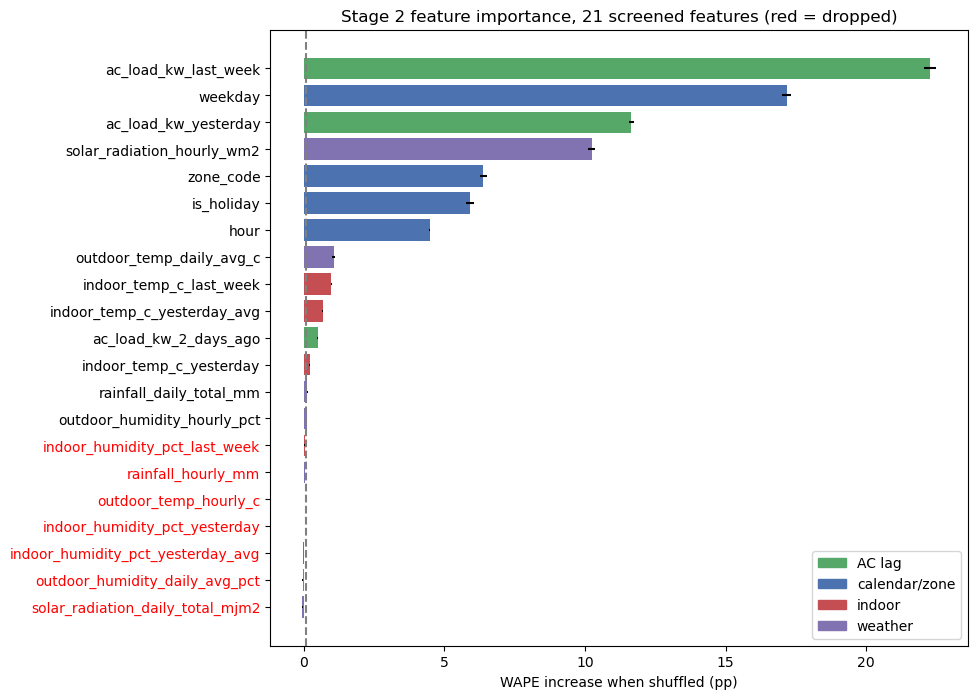

In [29]:
table = pd.DataFrame({
    "Group": comp["group"],
    "Stage 1": comp["stage1"],
    "SHAP kW": comp["mean_abs_shap_kW"],
    "Perm +pp": comp["perm_WAPE_increase_pp"],
    "Perm sd": comp["perm_sd_pp"],
    "Action": ["drop" if c in reasons else "keep" for c in comp.index],
}).round(2)
display(table)

colors = {"AC lag": "#55A868", "calendar/zone": "#4C72B0", "indoor": "#C44E52", "weather": "#8172B2"}
t = table.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(t.index, t["Perm +pp"], xerr=t["Perm sd"], color=t["Group"].map(colors))
ax.axvline(MIN_PERM_GAIN, ls="--", c="grey")
ax.set(xlabel="WAPE increase when shuffled (pp)",
       title=f"Stage 2 feature importance, {len(ALL_FEATURES)} screened features (red = dropped)")
for label in ax.get_yticklabels():
    label.set_color("red" if t.loc[label.get_text(), "Action"] == "drop" else "black")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], colors, loc="lower right")
fig.savefig(OUT_DIR / "feature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Remove low importance features in final model

Refit on the kept features only and compare against the full model on
validation. The reduced model is accepted if it lands within the WAPE
tolerance, on the grounds that it is simpler.

These drops are on top of the Stage 1 exclusions, so the final feature list is
what survived both stages.


In [31]:
banner("STEP 3/4  Drop weak / noisy features and check the reduced model on validation")
drop = MANUAL_DROP if MANUAL_DROP is not None else list(reasons)
KEPT = [c for c in ALL_FEATURES if c not in drop]
log(f"  Dropping {len(drop)}: {drop}")
log(f"  Keeping  {len(KEPT)}: {KEPT}")

tune_red, best_red = tune(KEPT, "reduced")
tune_red.to_csv(OUT_DIR / "tuning_reduced.csv", index=False)
red_op = best_red["val_WAPE_op%"]
full_op = best_full["val_WAPE_op%"]
log(f"\n  Validation WAPE (op hours): full {full_op:.2f}% vs reduced {red_op:.2f}% "
    f"({red_op - full_op:+.2f} pp)")
if red_op <= full_op + TOLERANCE:
    FINAL_FEATURES, best_final, choice = KEPT, best_red, "reduced"
    log(f"  -> reduced model accepted (within {TOLERANCE} pp tolerance, simpler)")
else:
    FINAL_FEATURES, best_final, choice = ALL_FEATURES, best_full, "full"
    log("  -> reduced model is worse; keeping all features. Try MANUAL_DROP with fewer drops.")

# What Stage 2 actually removed, after the accept / reject decision above
DROPPED_STAGE2 = [c for c in ALL_FEATURES if c not in FINAL_FEATURES]
log(f"\n  Across both stages: {len(dropped_stage1)} excluded by Stage 1 screening + "
    f"{len(DROPPED_STAGE2)} dropped here = {len(FINAL_FEATURES)} of "
    f"{len(dropped_stage1) + len(ALL_FEATURES)} original candidate features")



STEP 3/4  Drop weak / noisy features and check the reduced model on validation
  Dropping 7: ['indoor_humidity_pct_yesterday', 'indoor_humidity_pct_last_week', 'indoor_humidity_pct_yesterday_avg', 'outdoor_temp_hourly_c', 'outdoor_humidity_daily_avg_pct', 'rainfall_hourly_mm', 'solar_radiation_daily_total_mjm2']
  Keeping  14: ['zone_code', 'hour', 'weekday', 'is_holiday', 'ac_load_kw_yesterday', 'ac_load_kw_2_days_ago', 'ac_load_kw_last_week', 'indoor_temp_c_yesterday', 'indoor_temp_c_last_week', 'indoor_temp_c_yesterday_avg', 'outdoor_temp_daily_avg_c', 'outdoor_humidity_hourly_pct', 'rainfall_daily_total_mm', 'solar_radiation_hourly_wm2']


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [reduced 1/8] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 20} iter= 151 | val WAPE all 21.51% op 12.82% | 2s


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [reduced 2/8] {'objective': 'regression', 'num_leaves': 31, 'min_child_samples': 100} iter= 137 | val WAPE all 21.91% op 13.00% | 2s


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


... (7 outputs left out)

C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [reduced 7/8] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 20} iter= 730 | val WAPE all 19.70% op 12.81% | 8s


C:\Users\zheng\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


  [reduced 8/8] {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100} iter=2987 | val WAPE all 18.46% op 11.86% | 29s
  -> best reduced: {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100} iter=2987 val WAPE op 11.86%

  Validation WAPE (op hours): full 12.84% vs reduced 11.86% (-0.99 pp)
  -> reduced model accepted (within 0.1 pp tolerance, simpler)

  Across both stages: 3 excluded by Stage 1 screening + 7 dropped here = 14 of 24 original candidate features


## 4. Build Final Model

Retrain on train + validation (all of 2019) and predict the held-out 2018
test window.

In [33]:
banner(f"STEP 4/4  Retrain final ({choice}, {len(FINAL_FEATURES)} features) on all 2019, test on Jul-Sep 2018")
test_pred = test[["zone_id", "timestamp", "rainfall_hourly_mm"]].copy()
final_models = {}
for name, feats, best in [("LGBM full", ALL_FEATURES, best_full), ("LGBM final", FINAL_FEATURES, best_final)]:
    if name == "LGBM final" and choice == "full":
        test_pred[name] = test_pred["LGBM full"]
        final_models[name] = final_models["LGBM full"]
        continue
    n_iter = int(best["best_iter"] * len(full) / len(train))
    log(f"  {name}: {len(feats)} features, {n_iter} trees, {as_params(best)}")
    t = time.time()
    m = fit(as_params(best), full[feats], full[TARGET], n_estimators=n_iter,
            callbacks=[progress_callback(max(50, n_iter // 5), name)])
    test_pred[name] = predict(m, test[feats])
    final_models[name] = m
    log(f"  -> trained + predicted in {time.time() - t:.1f}s")

final_models["LGBM final"].booster_.save_model(str(OUT_DIR / "lgbm_final.txt"))

# Final feature list, with the Stage 1 note each surviving feature carried in
pd.DataFrame({"feature": FINAL_FEATURES,
              "group": [GROUP[c] for c in FINAL_FEATURES],
              "stage1": [STAGE1.at[c, "stage1"] for c in FINAL_FEATURES],
              "stage1_note": [STAGE1.at[c, "stage1_note"] for c in FINAL_FEATURES]}
             ).to_csv(OUT_DIR / "final_features.csv", index=False)

# One record of everything removed, by the stage that removed it
pd.concat([
    pd.DataFrame({"feature": dropped_stage1.column.tolist(),
                  "stage": "Stage 1 (pre-training screen)",
                  "reason": dropped_stage1.stage1_reason.tolist()}),
    pd.DataFrame({"feature": DROPPED_STAGE2,
                  "stage": "Stage 2 (permutation on validation)",
                  "reason": [reasons.get(c, "manual drop (MANUAL_DROP)") for c in DROPPED_STAGE2]}),
]).to_csv(OUT_DIR / "dropped_features.csv", index=False)



STEP 4/4  Retrain final (reduced, 14 features) on all 2019, test on Jul-Sep 2018
  LGBM full: 21 features, 190 trees, {'objective': 'regression', 'num_leaves': 63, 'min_child_samples': 100}
    [LGBM full] tree    50/190 ( 26.3%) | elapsed    0.7s | ETA    2.1s
    [LGBM full] tree   100/190 ( 52.6%) | elapsed    1.2s | ETA    1.0s
    [LGBM full] tree   150/190 ( 78.9%) | elapsed    1.5s | ETA    0.4s
    [LGBM full] tree   190/190 (100.0%) | elapsed    1.9s | ETA    0.0s
  -> trained + predicted in 2.3s
  LGBM final: 14 features, 4236 trees, {'objective': 'regression_l1', 'num_leaves': 63, 'min_child_samples': 100}
    [LGBM final] tree   847/4236 ( 20.0%) | elapsed    7.0s | ETA   28.0s
    [LGBM final] tree  1694/4236 ( 40.0%) | elapsed   13.5s | ETA   20.3s
    [LGBM final] tree  2541/4236 ( 60.0%) | elapsed   20.2s | ETA   13.5s
    [LGBM final] tree  3388/4236 ( 80.0%) | elapsed   26.4s | ETA    6.6s
    [LGBM final] tree  4235/4236 (100.0%) | elapsed   32.7s | ETA    0.0s
    

## Test

Score the predictions against the baselines on the out-of-year test period
(Jul-Sep 2018): headline metrics, rain vs dry, and a Diebold-Mariano test for
significance.

In [35]:
MODEL_COLS = ["LGBM full", "LGBM final"]
cmp = (baselines[baselines.period == "test"]
       .merge(test_pred, on=["zone_id", "timestamp"], how="left"))
cmp = cmp[cmp.scored == 1].copy()
assert cmp[BASELINES + MODEL_COLS].notna().all().all(), "missing predictions on scored rows"
cmp.to_parquet(OUT_DIR / "test_predictions.parquet", index=False)


In [37]:
rows = []
for hours, mask in [("all hours", np.ones(len(cmp), bool)),
                    ("operating hours", cmp.is_operating_hours.eq(1).values)]:
    for c in BASELINES + MODEL_COLS:
        rows.append({"hours": hours, "model": c, **metrics(cmp.loc[mask, TARGET], cmp.loc[mask, c])})
results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "test_metrics.csv", index=False)


In [39]:
op = cmp[cmp.is_operating_hours.eq(1)]
rain = pd.DataFrame([{"condition": n, "model": c, "WAPE%": wape(s[TARGET], s[c])}
                     for n, s in [("dry", op[op.rainfall_hourly_mm.eq(0)]),
                                  ("rain", op[op.rainfall_hourly_mm.gt(0)])]
                     for c in BASELINES + MODEL_COLS]).pivot(index="model", columns="condition", values="WAPE%")
rain.to_csv(OUT_DIR / "test_rain_vs_dry.csv")


In [41]:
def diebold_mariano(frame, a, b, max_lag=24):
    """DM on absolute error, averaged across zones per hour; Newey-West variance.
    DM < 0 => model a is more accurate than b."""
    d = (np.abs(frame[TARGET] - frame[a]) - np.abs(frame[TARGET] - frame[b]))
    d = d.groupby(frame.timestamp).mean().sort_index().values
    n, dbar = len(d), d.mean()
    dc = d - dbar
    lrv = dc @ dc / n
    for k in range(1, max_lag + 1):
        lrv += 2 * (1 - k / (max_lag + 1)) * (dc[k:] @ dc[:-k]) / n
    dm = dbar / np.sqrt(lrv / n)
    return dm, 2 * stats.norm.sf(abs(dm))
    

In [43]:
dm_rows = []
for hours, frame in [("all hours", cmp), ("operating hours", op)]:
    for b in BASELINES + (["LGBM full"] if choice == "reduced" else []):
        dm, p = diebold_mariano(frame, "LGBM final", b)
        dm_rows.append({"hours": hours, "model": "LGBM final", "vs": b, "DM": dm, "p_value": p})
dm_tab = pd.DataFrame(dm_rows)
dm_tab.to_csv(OUT_DIR / "test_diebold_mariano.csv", index=False)


## Results (Using WAPE%)

Printed summary and WAPE bar charts for all hours and operating hours.

In [45]:
banner("RESULTS (test = Jul-Sep 2018, scored rows)")
log(results.to_string(index=False))
log("\nRain vs dry (operating hours, WAPE%):")
log(rain.to_string())
log("\nDiebold-Mariano (DM < 0 => LGBM final more accurate):")
log(dm_tab.to_string(index=False))
log(f"\nDone in {(time.time() - t0) / 60:.1f} min. Outputs in {OUT_DIR.resolve()}")



RESULTS (test = Jul-Sep 2018, scored rows)
          hours                 model     n      MAE     RMSE  CV(RMSE)%      NMBE%     WAPE%
      all hours     B1 seasonal naive 46064 1.197930 4.151608  98.179932  -1.270936 28.329428
      all hours    B2 average profile 46064 1.146502 3.002205  70.998098  -7.763172 27.113222
      all hours B3 calendar + AC lags 46064 1.673616 3.402832  80.472406 -12.111553 39.578769
      all hours             LGBM full 46064 0.954080 2.661488  62.940610  -3.053916 22.562710
      all hours            LGBM final 46064 0.814411 2.724022  64.419462   2.266199 19.259718
operating hours     B1 seasonal naive 12602 2.313099 4.768478  34.872136   4.700967 16.915814
operating hours    B2 average profile 12602 2.661834 3.846530  28.129883 -11.834572 19.466136
operating hours B3 calendar + AC lags 12602 2.478267 4.022169  29.414334   4.067092 18.123696
operating hours             LGBM full 12602 1.734292 2.732631  19.983878  -1.450970 12.682972
operating hours 

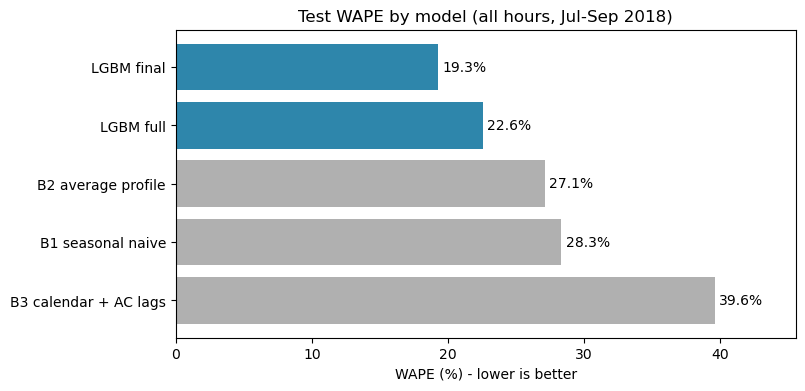

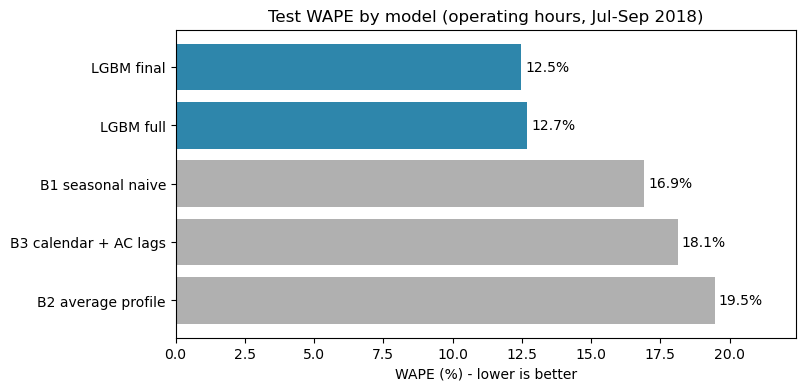

In [47]:
for hours in ["all hours", "operating hours"]:
    r = results[results.hours == hours].sort_values("WAPE%", ascending=False)
    colors = ["#2E86AB" if m.startswith("LGBM") else "#B0B0B0" for m in r.model]
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(r.model, r["WAPE%"], color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set(xlabel="WAPE (%) - lower is better", title=f"Test WAPE by model ({hours}, Jul-Sep 2018)")
    ax.set_xlim(0, r["WAPE%"].max() * 1.15)
    fig.savefig(OUT_DIR / f"wape_{hours.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    try:
        display(fig)          # Jupyter / Colab
    except NameError:
        pass                  # plain script: chart is saved only
    plt.close(fig)


## Export final model as wrapper

Export the final model as a reusable wrapper (for the web app)

In [49]:
from ac_forecaster import ACLoadForecaster# E

op_test = results[(results.hours == "operating hours") & (results.model == "LGBM final")].iloc[0]
forecaster = ACLoadForecaster.from_model(
    final_models["LGBM final"], FINAL_FEATURES, df,
    metadata={"target": TARGET, "trained_on": "2019 (train + validation)", "params": as_params(best_final),
              "data": "question_b_model_data_screened.parquet (Stage 1 screened)",
              "feature_selection": f"Stage 1 excluded {len(dropped_stage1)}, Stage 2 dropped {len(DROPPED_STAGE2)}, {len(FINAL_FEATURES)} kept",
              "test_WAPE_op%": round(float(op_test["WAPE%"]), 2), "test_CVRMSE_op%": round(float(op_test["CV(RMSE)%"]), 2)})
log(f"Saved {forecaster} to {forecaster.save(OUT_DIR / 'ac_forecaster')}")

Saved ACLoadForecaster(14 features, 23 zones, 4236 trees) to outputs\ac_forecaster
